## Cumulative responsibility of greenhouse gas emissions in Germany

In [1]:
import numpy as np
import pandas as pd

## Introduction

## Data Loading and Processing

### Data structure

In [2]:
raw_df = pd.read_csv(
        "../data:/85111-0005_en_flat.csv",
        sep=';',                    # Destatis commonly uses semicolons
        encoding='utf-8'            # Use 'cp1252' if utf-8 throws an error
    )

| Column Name | Description | Data Examples |
| :--- | :--- | :--- |
| **time** | Measurement Year | 2000, 2005, 2023... |
| **2_variable_attribute_label** | Emission Source (Broad Category) | Energy use, Road transport, Other processes |
| **3_variable_attribute_label** | Greenhouse Gas Type | Carbon dioxide ($CO_2$), Methane ($CH_4$), Total, etc. |
| **4_variable_attribute_label** | Industry Sector (WZ 2008) | Manufacture of paper, Fishing, etc. (Total 67 sectors) |
| **value_variable_label** | Emission Accounting Standard | Kyoto Protocol Total, All economic activities, Private households, etc. |
| **value** | Actual Emission Value | 4262142.558 (Numeric) |
| **value_unit** | Unit of Measurement | $t\ CO_2eq$ (tonnes of $CO_2$ equivalent) |

#### Macro data - national emission by year

In [3]:
# Filter data - only extract total emissions of year
total_em = raw_df[
    (raw_df['value_variable_label'] == 'Total greenhouse gas emissions acc. Kyoto Protocol') &
    (raw_df['3_variable_attribute_label'] == 'Total') # Using Total CO2e
].copy()

# Data type checking - change object data to numeric data for calculating
total_em['value'] = pd.to_numeric(total_em['value'], errors='coerce')

# Data accumulation - calculating sum emissions of all 3 sub-groups (Energy use, Road transport, Other processes)
total_em = total_em.groupby('time')['value'].sum().reset_index()

# Change the data column name
total_em = total_em[['time', 'value']].rename(columns={
    'time': 'year', 
    'value': 'emission'
}).reset_index(drop=True)

In [4]:
total_em.head()

,year,emission
0,2000,1.069205e+09
1,2001,1.087054e+09
2,2002,1.066397e+09
3,2003,1.070541e+09
4,2004,1.058412e+09


#### Micro data - sectoral emissions by year

1. Greenhouse gas emiss. of all economic activities (18 Sectors) +  Greenhouse gas emissions of private households =  Greenh. gas emissions of nationals (Total 19 Sectors)

In [5]:
# Filter data - only extract sectoral emissions
sector_em_raw = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emissions') &
    (raw_df['3_variable_attribute_label'] == 'Total') &
    (raw_df['4_variable_attribute_code'].str.match(r'^WZ08-[A-Z]+(-[A-Z]+)*$', na=False)) # Not include all 67 sectors, only include higher economic sector classification (e.g., WZ08-A)
].copy()

# Convert value to numeric (crucial for correct summation)
sector_em_raw['value'] = pd.to_numeric(sector_em_raw['value'], errors='coerce')

# Rename the column of data
rename_dict = {
    "time": "year",
    "4_variable_attribute_label": "sector_name",
    "4_variable_attribute_code": "sector_code",
    "2_variable_attribute_label": "source",
    "value": "emission"
}
sector_em = sector_em_raw[list(rename_dict.keys())].rename(columns=rename_dict)

# Calculate the sum for whole sectors by sector_em_raw data
calculated_total = sector_em.groupby('year')['emission'].sum()

# Test the data with offical sum data for validating 
official_sector_total = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emiss. of all economic activities') &
    (raw_df['3_variable_attribute_label'] == 'Total')
].copy()
official_sector_total['value'] = pd.to_numeric(official_sector_total['value'], errors='coerce') 
official_sector_total_series = official_sector_total.groupby('time')['value'].sum()

comparison = np.isclose(calculated_total, official_sector_total_series)
if comparison.all():
    print("Match")
else:
    mismatched_years = calculated_total.index[~comparison]
    print(f"Mismatch found in years: {list(mismatched_years)}")

Match


In [6]:
household_raw = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emissions of private households') &
    (raw_df['3_variable_attribute_label'] == 'Total')
].copy()
household_df = household_raw.rename(columns={
    "time": "year",
    "2_variable_attribute_label": "source",
    "value": "emission"
})
household_df["sector_name"] = "Private Households"
household_df["sector_code"] = "HH"  # Dummy code for households
target_columns = ["year", "sector_name", "sector_code", "source", "emission"]
household_df = household_df[target_columns].copy()

# 5. Convert emission to numeric to avoid 'object' type issues
household_df["emission"] = pd.to_numeric(household_df["emission"], errors="coerce")
sector_em = pd.concat([sector_em, household_df], ignore_index=True)

In [7]:
sector_em.head()

,year,sector_name,sector_code,source,emission
0,2008,Mining and quarrying,WZ08-B,Other processes,5.226395e+06
1,2010,"Electricity, gas, steam, air conditioning supply",WZ08-D,Road transport,6.625116e+05
2,2002,Human health and social work activities,WZ08-Q,Energy use,6.876039e+06
3,2017,"Water supply,sewerage,waste management,remedia...",WZ08-E,Other processes,1.176431e+07
4,2010,Mining and quarrying,WZ08-B,Other processes,3.879621e+06


2. Sub-sectors (19 sub-sectors) of Manufacturing sector

In [8]:
# Filter data - only extract manufacturing sub-sector emissions (WZ08-10 to WZ08-33)
mfg_sub_list = ['WZ08-10-03', 'WZ08-13-04', 'WZ08-16', 'WZ08-17', 'WZ08-18', 'WZ08-19', 'WZ08-20', 'WZ08-21','WZ08-22', 'WZ08-23', 'WZ08-24', 'WZ08-25', 'WZ08-26', 'WZ08-27', 'WZ08-28', 'WZ08-29', 'WZ08-30', 'WZ08-31-02', 'WZ08-33']
mfg_sub_raw = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emissions') &
    (raw_df['3_variable_attribute_label'] == 'Total') &
    (raw_df['4_variable_attribute_code'].isin(mfg_sub_list)) # Simple and precise
].copy()

# Convert value to numeric (crucial for correct summation)
mfg_sub_raw['value'] = pd.to_numeric(mfg_sub_raw['value'], errors='coerce')

# Rename the column of data
rename_dict = {
    "time": "year",
    "4_variable_attribute_label": "sector_name",
    "4_variable_attribute_code": "sector_code",
    "2_variable_attribute_label": "source",
    "value": "emission"
}
mfg_sub_em = mfg_sub_raw[list(rename_dict.keys())].rename(columns=rename_dict)

# Calculate the sum for manufacturing sub-sectors by mfg_sub_em data
calculated_mfg_total = mfg_sub_em.groupby('year')['emission'].sum()

# Extract official WZ08-C (Manufacturing parent) total for validating 
# Comparing against the parent sector 'WZ08-C' to ensure sub-sectors sum up correctly
official_mfg_parent = raw_df[
    (raw_df['value_variable_label'] == 'Greenhouse gas emissions') &
    (raw_df['3_variable_attribute_label'] == 'Total') &
    (raw_df['4_variable_attribute_code'] == 'WZ08-C')
].copy()

official_mfg_parent['value'] = pd.to_numeric(official_mfg_parent['value'], errors='coerce') 
official_mfg_parent_series = official_mfg_parent.groupby('time')['value'].sum()

# Test the data with official parent sector data for validating 
comparison = np.isclose(calculated_mfg_total, official_mfg_parent_series)
if comparison.all():
    print("Match")
else:
    mismatched_years = calculated_mfg_total.index[~comparison]
    print(f"Mismatch found in years: {list(mismatched_years)}")

Match


In [9]:
mfg_sub_em.head()

,year,sector_name,sector_code,source,emission
2881,2021,Manufacture of other transport equipment,WZ08-30,Energy use,3.995959e+05
2884,2006,Manufacture of coke and refined petroleum prod...,WZ08-19,Energy use,2.948588e+07
2907,2015,Manufacture of coke and refined petroleum prod...,WZ08-19,Road transport,6.238636e+04
2993,2017,"Manuf. of motor vehicles, trailers, semi-trailers",WZ08-29,Road transport,8.055341e+05
2994,2020,Manufacture of machinery and equipment n.e.c.,WZ08-28,Road transport,5.395990e+05


#### Global greenhouse gas emissions data

Mega ton -> ton 

In [ ]:
edgar_df = pd.read_csv('../data:/EDGAR_2025_GHG.csv')

# Reshape the data (Wide to Long)
em_id_cols = ['EDGAR Country Code', 'Country']
em_year_cols = [col for col in edgar_df.columns if col not in em_id_cols]

global_em = edgar_df.melt(
    id_vars=em_id_cols, 
    var_name='year', 
    value_name='emission_Mt'
)

# Renaming
global_em = global_em.rename(columns={
    'EDGAR Country Code': 'country_code',
    'Country': 'country_name_em'
})

# Numeric conversion
global_em['year'] = pd.to_numeric(global_em['year'])
global_em['emission'] = pd.to_numeric(global_em['emission_Mt'], errors='coerce')
global_em['emission'] = global_em['emission_Mt'] * 10**6 # Mega ton to ton
global_em = global_em.drop(columns=['emission_Mt'])

In [11]:
global_em.head()

,country_code,country_name_em,year,emission
0,ABW,Aruba,1970,3.696956e+04
1,AFG,Afghanistan,1970,1.529996e+07
2,AGO,Angola,1970,1.883435e+07
3,AIA,Anguilla,1970,3.397521e+03
4,AIR,International Aviation,1970,1.724780e+08


#### Global population data

In [39]:
pop_df = pd.read_csv('../data:/WPP2024_GEN_F01_DEMOGRAPHIC_INDICATORS_COMPACT.csv')

# Renaming for consistency
global_pop = pop_df.rename(columns={
    'Country Code': 'country_code',
    'Country Name': 'country_name_pop',
    'Year': 'year',
    'Population': 'population'
})

# Select only the necessary columns for the carbon budget allocation
global_pop = global_pop[['country_name_pop', 'country_code', 'year', 'population']]

# Convert 'year' and 'population' to numeric types to prevent downstream calculation errors
global_pop['year'] = pd.to_numeric(global_pop['year'])
global_pop['population'] = pd.to_numeric(global_pop['population'])

In [40]:
global_pop.head()

,country_name_pop,country_code,year,population
0,Burundi,BDI,1950,2229322
1,Burundi,BDI,1951,2280554
2,Burundi,BDI,1952,2330938
3,Burundi,BDI,1953,2380670
4,Burundi,BDI,1954,2429703


#### Global Emission + Population merged data

In [64]:
# 1. Identify countries present in both datasets to maintain the "inner join" logic for countries
valid_countries = set(global_em['country_code']).intersection(set(global_pop['country_code']))

# Filter both datasets to keep only valid countries
em_filtered = global_em[global_em['country_code'].isin(valid_countries)]
pop_filtered = global_pop[global_pop['country_code'].isin(valid_countries)]

# 2. Outer Join to keep future years from population data (where emissions data is NaN)
merged_global = pd.merge(
    em_filtered, 
    pop_filtered[['country_code', 'year', 'population']], 
    on=['country_code', 'year'], 
    how='outer' 
)

# 3. Clean up: Remove rows where population is missing (do not drop by 'emission' as future years lack emission data)
merged_global = merged_global.dropna(subset=['population'])

# Filter for the extended analysis period (1970 to 2100 to include future projections)
# You can change 2100 to 2050 depending on your target demographic window
merged_global = merged_global[merged_global['year'].between(1970, 2100)]

# Verification
print(f"Number of unique countries after merge: {merged_global['country_code'].nunique()}")
print(f"Years available: {merged_global['year'].min()} - {merged_global['year'].max()}")

Number of unique countries after merge: 206
Years available: 1970 - 2100


In [72]:
# 1. Extract unique country codes as sets
em_codes = set(global_em['country_code'].dropna().unique())
pop_codes = set(global_pop['country_code'].dropna().unique())

# 2. Calculate intersection and differences using set operations
overlapping_codes = em_codes.intersection(pop_codes)
only_in_em = em_codes - pop_codes
only_in_pop = pop_codes - em_codes

# Print the number of overlapping and non-overlapping countries
print(f"Number of overlapping countries: {len(overlapping_codes)}")
print(f"Number of countries ONLY in Emission data: {len(only_in_em)}")
print(f"Number of countries ONLY in Population data: {len(only_in_pop)}\n")

# 3. Display the specific countries missing from either dataset
# Use drop_duplicates() to show each country only once
if len(only_in_em) > 0:
    print("--- Countries in Emission data BUT NOT in Population data ---")
    missing_in_pop = global_em[global_em['country_code'].isin(only_in_em)][['country_code', 'country_name_em']].drop_duplicates()
    print(missing_in_pop.to_string(index=False))
    print("\n")

if len(only_in_pop) > 0:
    print("--- Countries in Population data BUT NOT in Emission data ---")
    missing_in_em = global_pop[global_pop['country_code'].isin(only_in_pop)][['country_code', 'country_name_pop']].drop_duplicates()
    print(missing_in_em.to_string(index=False))

Number of overlapping countries: 206
Number of countries ONLY in Emission data: 6
Number of countries ONLY in Population data: 31

--- Countries in Emission data BUT NOT in Population data ---
country_code        country_name_em
         AIR International Aviation
         ANT                Curaçao
         SCG  Serbia and Montenegro
         SEA International Shipping
        EU27                   EU27
GLOBAL TOTAL           GLOBAL TOTAL


--- Countries in Population data BUT NOT in Emission data ---
country_code                 country_name_pop
         MYT                          Mayotte
         SSD                      South Sudan
         PSE               State of Palestine
         GGY                         Guernsey
         IMN                      Isle of Man
         JEY                           Jersey
         AND                          Andorra
         VAT                         Holy See
         XKX    Kosovo (under UNSC res. 1244)
         MNE                   

In [73]:
merged_global.head()

,country_code,country_name_em,year,emission,population
20,ABW,Aruba,1970,36969.560,59020
21,ABW,Aruba,1971,41825.240,58881
22,ABW,Aruba,1972,52708.352,58680
23,ABW,Aruba,1973,57704.309,59111
24,ABW,Aruba,1974,56999.430,59760


## Research Questions

### 1. How have greenhouse gas emissions changed across sectors, and which sector has been the most prominent contributor over the past 20 years?

In [231]:
%load_ext autoreload
%autoreload 2

from Visualization import assign_action_tiers, plot_strategic_quadrant, plot_tiered_ranking, generate_svg_line_sparkline, generate_enhanced_mfg_table
import plotly.express as px
from IPython.display import display, HTML

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [232]:
tier_metrics = assign_action_tiers(sector_em, start_year=2000, end_year=2023)

# 4 Matrix
plot_strategic_quadrant(tier_metrics, target_year=2023)

# Tier ranking - bar graph
plot_tiered_ranking(tier_metrics, target_year=2023)

--- Methodology Note ---
National Avg Reduction (2000-2023): -25.39%
Pareto Threshold: Top sectors up to 85% cumulative share are 'Major'


In [233]:
mfg_html_table = generate_enhanced_mfg_table(mfg_sub_em, start_year=2000, end_year=2023, top_n=9)
display(HTML(mfg_html_table))

,year,Share (%),Trend (2000-2023),Direction,Growth Rate (%)
sector_code,sector_name,,,,
WZ08-24,Manufacture of basic metals,27.64,"<polyline points=""0.0,2.3788775946651626 5.217391304347826,10.299614211034392 10.434782608695652,10.347321314595806 15.652173913043478,10.322928637717924 20.869565217391305,8.958308905522642 26.086956521739133,9.492317397915818 31.304347826086957,5.036520354549172 36.52173913043478,3.080447863846892 41.73913043478261,5.076427956440526 46.95652173913044,25.0 52.173913043478265,7.913554889574005 57.391304347826086,9.295141740625649 62.608695652173914,12.600265150113584 67.82608695652173,11.383707442398478 73.04347826086956,10.361534961827992 78.26086956521739,2.5888566329377873 83.47826086956522,3.5670526515831114 88.69565217391305,0.0 93.91304347826087,1.9425964519146355 99.1304347826087,5.386679495262037 104.34782608695653,14.153678712378841 109.56521739130434,4.986677326299372 114.78260869565217,11.062155203742646 120.0,12.735784348367572"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-14.00
WZ08-23,Manufacture of other non-metallic mineral products,16.21,"<polyline points=""0.0,0.0 5.217391304347826,7.52292104659049 10.434782608695652,10.902220868428028 15.652173913043478,7.86933753311456 20.869565217391305,4.846710320744673 26.086956521739133,11.915584258816942 31.304347826086957,8.863095111616168 36.52173913043478,4.802472111818425 41.73913043478261,6.802376429382235 46.95652173913044,14.647542784298993 52.173913043478265,13.970995768071456 57.391304347826086,10.765261736286808 62.608695652173914,13.047563717762504 67.82608695652173,14.5554110898354 73.04347826086956,13.770511979662642 78.26086956521739,15.060382020701853 83.47826086956522,14.951953354334496 88.69565217391305,12.768344042181774 93.91304347826087,13.346139247437932 99.1304347826087,14.09773954800521 104.34782608695653,11.08411911746996 109.56521739130434,12.63365257052755 114.78260869565217,16.506473581495392 120.0,25.0"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-31.15
WZ08-20,Manufacture of chemicals and chemical products,14.39,"<polyline points=""0.0,0.46178713542756 5.217391304347826,0.0 10.434782608695652,0.15118902600072204 15.652173913043478,6.216941168104768 20.869565217391305,5.430584038389778 26.086956521739133,8.965702422012605 31.304347826086957,12.759627989737304 36.52173913043478,4.1352619357604254 41.73913043478261,2.899857317776906 46.95652173913044,6.611418732609334 52.173913043478265,11.244984270536559 57.391304347826086,10.703217754568012 62.608695652173914,10.901246052610233 67.82608695652173,12.43424567165434 73.04347826086956,14.417049840628405 78.26086956521739,14.335930561067228 83.47826086956522,13.448039416354824 88.69565217391305,11.336877597336098 93.91304347826087,16.582628161874858 99.1304347826087,18.218899018635504 104.34782608695653,16.6678599736696 109.56521739130434,15.476963079147296 114.78260869565217,22.200045043103415 120.0,25.0"" fill=""none"" stroke=""#555555"" stroke-width=""2"" stroke-linejoin=""round""/>",▼,-39.04
WZ08-19,Manufacture of coke and refined petroleum products,14.10,"<polyline points=""0.0,4.6332395001912765 5.217391304347826,8.514548549916206 10.434782608695652,8.540578036891205 15.652173913043478,14.290626623945721 20.869565217391305,8.997315347694997 26.086956521739133,0.0 31.304347826086957,6.327024588605525 36.52173913043478,9.312207936878744 41.73913043478261,5.3132281277960764 46.95652173913044,2.5322223217788142 52.173913043478265,8.779634857485753 57.391304347826086,8.909464983167652 62.608695652173914,9.326772975098024 67.82608695652173,3.0079360527907326 73.04347826086956,6.799336771322601 78.26086956521739,5.902792990101084 83.47826086956522,4.249049570501505 88.69565217391305,4.9933867770000475 93.91304347826087,14.500417989825811 99.1304347826087,17.09137562774941 104.34782608695653,20.43657211188015 109.56521739130434,19.728377719960882 114.78260869565217,13.480830455233532 120.0,

Among 18 High Sectors : Electricity, Private House Holds, Manufacturing
Among manufaturing sub-sectors : Manufature of metals, non-metalic mineral products, chemical products, petroleum products. 

### 2. How responsible are Germany’s cumulative greenhouse gas emissions for the global carbon budget?

In [234]:
# 1. Filter global emissions data for the period 2020-2023
emissions_2020_to_2023 = merged_global[merged_global['year'].between(2020, 2023)]

# 2. Calculate the total global emissions for these 4 years in tonnes
total_emissions_tonnes = emissions_2020_to_2023['emission'].sum()

# 3. Convert tonnes to Gigatonnes (Gt)
# 1 Gt = 1,000,000,000 tonnes (10^9)
total_emissions_gt = total_emissions_tonnes / 1e9

print(f"Total global emissions from 2020 to 2023: {total_emissions_gt:.2f} GtCO2")

# 4. Calculate the Remaining Global Carbon Budget for 2024 (CB_global_2024)
# IPCC budgets as of early 2020
budget_2020_1_5C = 400.0  # GtCO2 for 1.5 degrees
budget_2020_2_0C = 1150.0 # GtCO2 for 2.0 degrees

# Deduct the emissions of 2020-2023 from the initial budgets
cb_global_2024_1_5C = budget_2020_1_5C - total_emissions_gt
cb_global_2024_2_0C = budget_2020_2_0C - total_emissions_gt

# Display the final updated budgets for 2024
print("--- Remaining Global Carbon Budget (As of 2024) ---")
print(f"For 1.5 degrees target: {cb_global_2024_1_5C:.2f} GtCO2")
print(f"For 2.0 degrees target: {cb_global_2024_2_0C:.2f} GtCO2")

Total global emissions from 2020 to 2023: 199.64 GtCO2
--- Remaining Global Carbon Budget (As of 2024) ---
For 1.5 degrees target: 200.36 GtCO2
For 2.0 degrees target: 950.36 GtCO2


In [235]:
# Import the function from the external .py file
# Note: Ensure budget_calculator.py is in the same directory as this notebook
from carbonbudget import calculate_adjusted_carbon_budgets, plot_germany_carbon_analysis

# Set your target budget (e.g., the 1.5C remaining budget for 2024)
TARGET_BUDGET_1_5C = cb_global_2024_1_5C  

# Call the function and store the result in a variable
result_1_5C = calculate_adjusted_carbon_budgets(merged_global, target_budget=TARGET_BUDGET_1_5C)

# Display the first 10 rows (Countries with largest deficit) as a styled table in Jupyter
result_1_5C.head(10)

,country_name_em,country_code,debt,fair_share,adjusted_budget
194,United States,USA,253.040391,8.193128,-244.847263
158,Russia,RUS,77.423651,3.143613,-74.280038
48,Germany,DEU,33.222000,1.829462,-31.392537
31,Canada,CAN,25.807279,0.966859,-24.840420
97,Japan,JPN,26.553870,2.580408,-23.973463
9,Australia,AUS,20.320667,0.665003,-19.655665
67,United Kingdom,GBR,18.015179,1.635289,-16.379890
160,Saudi Arabia,SAU,16.002026,0.915787,-15.086239
192,Ukraine,UKR,15.659084,0.812755,-14.846329
149,Poland,POL,14.204021,0.805700,-13.398321


In [236]:
# Set your target budget (e.g., the 1.5C remaining budget for 2024)
TARGET_BUDGET_2_0C = cb_global_2024_2_0C 

# Call the function and store the result in a variable
result_2_0C = calculate_adjusted_carbon_budgets(merged_global, target_budget=TARGET_BUDGET_2_0C)

# Display the first 10 rows (Countries with largest deficit) as a styled table in Jupyter
result_2_0C.head(10)

,country_name_em,country_code,debt,fair_share,adjusted_budget
194,United States,USA,253.040391,38.862679,-214.177711
158,Russia,RUS,77.423651,14.911182,-62.512469
48,Germany,DEU,33.222000,8.677737,-24.544262
31,Canada,CAN,25.807279,4.586127,-21.221152
9,Australia,AUS,20.320667,3.154325,-17.166343
97,Japan,JPN,26.553870,12.239715,-14.314155
192,Ukraine,UKR,15.659084,3.855163,-11.803921
160,Saudi Arabia,SAU,16.002026,4.343876,-11.658150
149,Poland,POL,14.204021,3.821699,-10.382323
67,United Kingdom,GBR,18.015179,7.756711,-10.258469


### 3. How many years are left before the global and Germany’s carbon budgets are exhausted under business-as-usual emissions?

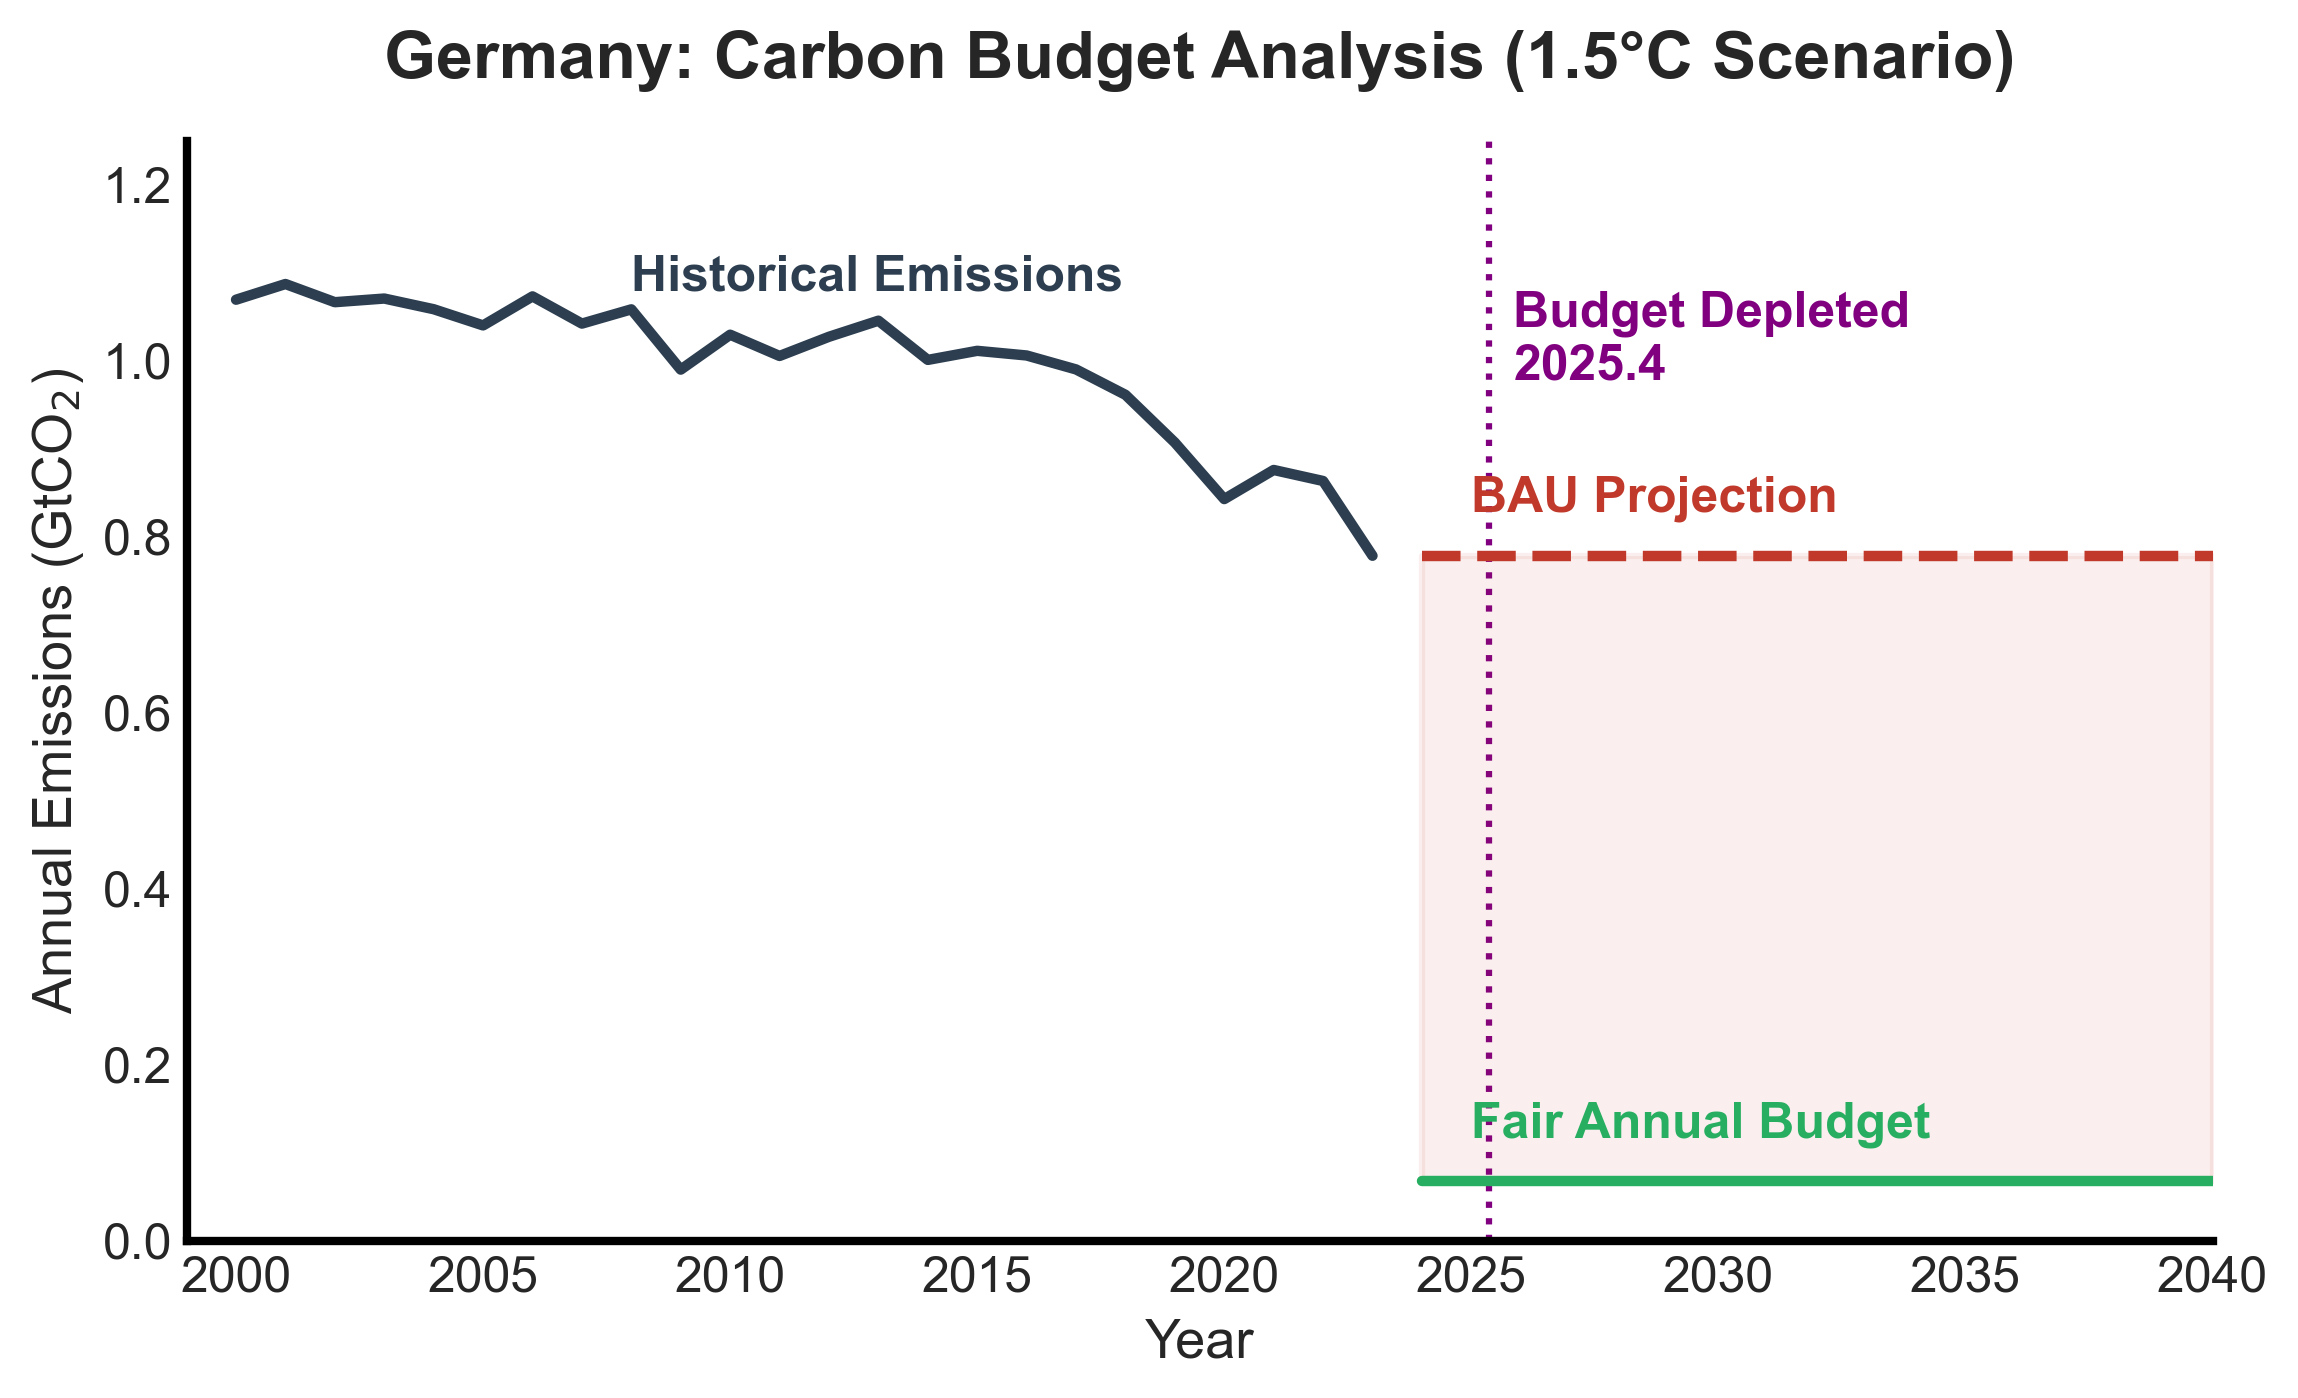


  ANALYSIS SUMMARY FOR GERMANY (DEU) | 1.5°C SCENARIO
  ● Allocated Fair Share (2024-2050)      : 1.83 GtCO2
  ● Current Annual Emission (2023)        : 0.78 GtCO2
  ● Time left under BAU                   : 2.35 years
  ● Actual Time (Depletion Date)          : 2025.4
  ● Individual fair allowance             : 21.60 tCO2 per person (Total until 2050)



In [237]:
plot_germany_carbon_analysis(result_1_5C, merged_global, total_em, "1.5")

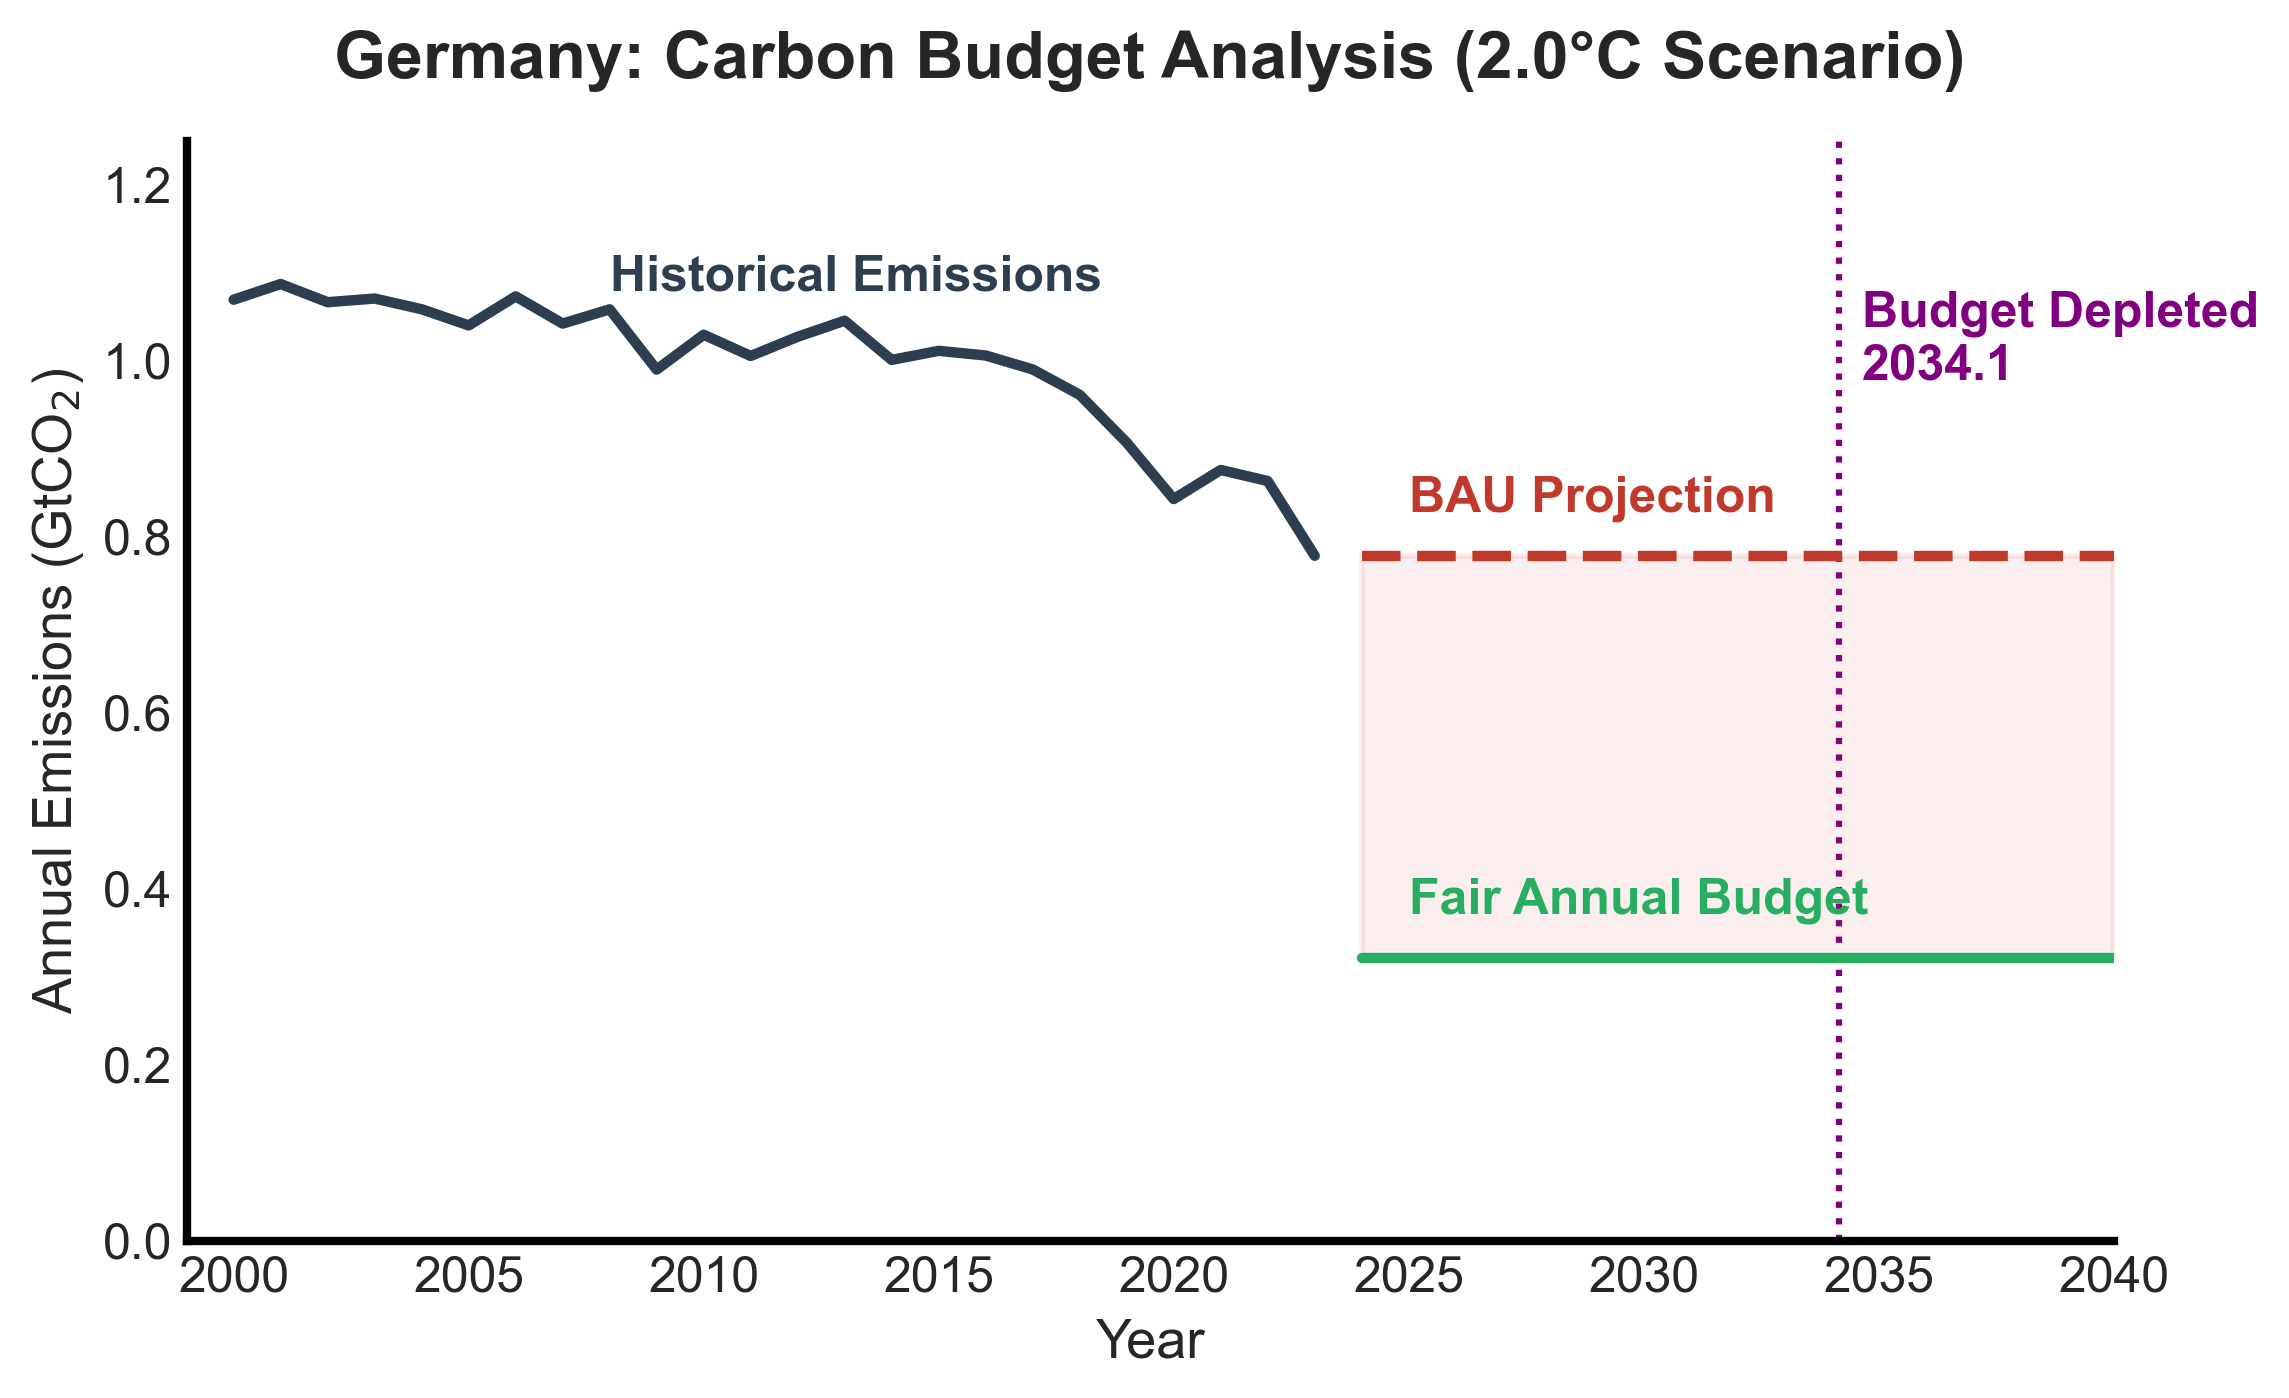


  ANALYSIS SUMMARY FOR GERMANY (DEU) | 2.0°C SCENARIO
  ● Allocated Fair Share (2024-2050)      : 8.68 GtCO2
  ● Current Annual Emission (2023)        : 0.78 GtCO2
  ● Time left under BAU                   : 11.15 years
  ● Actual Time (Depletion Date)          : 2034.1
  ● Individual fair allowance             : 102.46 tCO2 per person (Total until 2050)



In [238]:
plot_germany_carbon_analysis(result_2_0C, merged_global, total_em, "2.0")

### 4. How steep must the total emissions reduction pathway be to achieve net-zero by 2045 ?

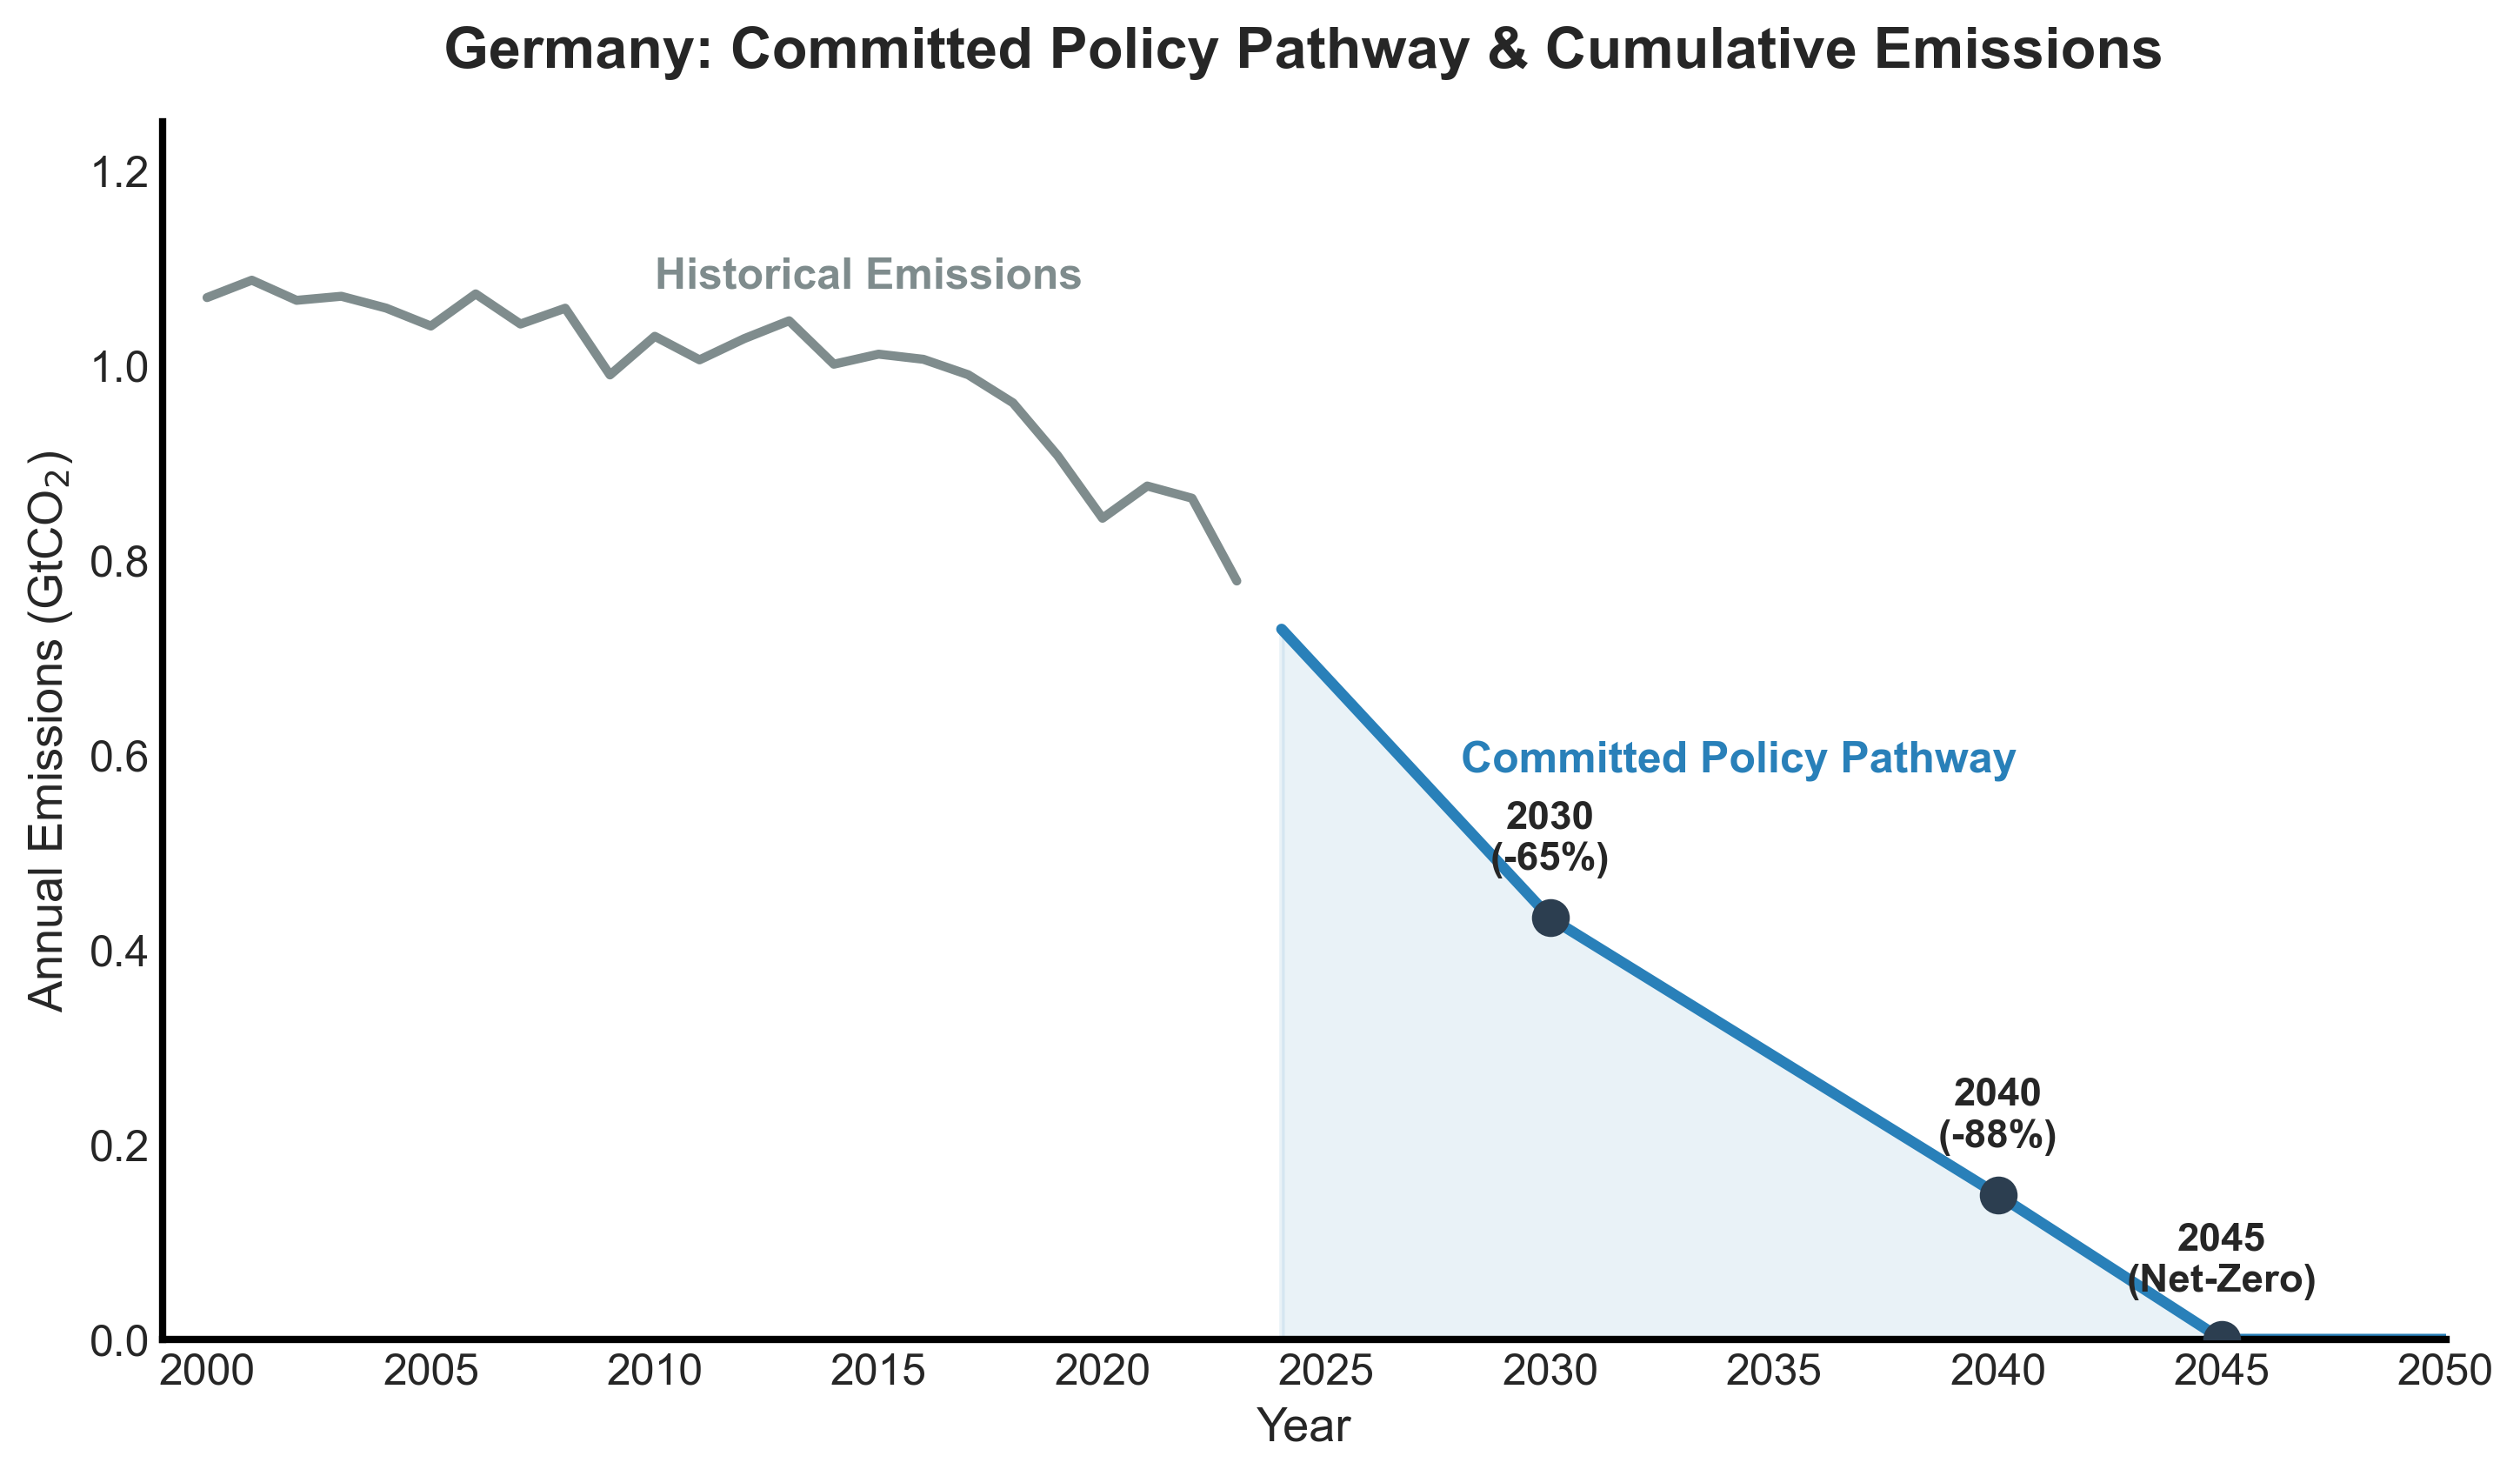

  ANALYSIS: GERMANY'S COMMITED PATHWAY VS GLOBAL FAIR SHARE (1.5°C vs 2.0°C)
  [1] Required Steepness of Policy Pathway
      ● 2024 - 2030 : -8.1% per year
      ● 2030 - 2040 : -10.2% per year
      ● 2040 - 2045 : 100% phase-out to Net-Zero
      ▶ Total Cumulative Emissions (2024-2050) : 7.12 GtCO2
--------------------------------------------------------------------------------
  [2] The Reality Check: True Overshoot & Debt Comparison
      Metric                        | 1.5°C Target       | 2.0°C Target
      ------------------------------------------------------------------
      Future Fair Share (2024-2050) |   1.83 GtCO2      |   8.68 GtCO2
      Fair Share OVERSHOOT (Future) |   5.29 GtCO2      |  -1.55 GtCO2
      Historical Debt (1970-2023)   |  33.22 GtCO2      |  33.22 GtCO2
      TRUE OVERSHOOT (Total CDR)    |  38.52 GtCO2      |  31.67 GtCO2
      ------------------------------------------------------------------
      ▶ Equivalent to (2023 basis)  |  49.5 Years      

In [239]:
from netzeroanalysis import analyze_policy_pathway

e_1990 = float(merged_global[(merged_global['country_code'] == 'DEU') & (merged_global['year'] == 1990)]['emission'].iloc[0])
e_1990_gt = e_1990 / 1e9
analyze_policy_pathway(result_1_5C, result_2_0C, total_em, e_1990_gt=e_1990_gt)

## Conclusion and Discussion

### Summary of Findings

## References

### Primary Sources
1. 

### Cumulative world emissions data
1. 

### Cumulative world emissions data
1. 